# Tail Dependence (Joint Crashes)

**Family:** Finance & investment &nbsp;|&nbsp; **Library:** matplotlib / seaborn &nbsp;|&nbsp; **Level:** Advanced

> *Finance & investment:* Performance, risk, portfolios, markets, rates, derivatives and valuation, the everyday charts of investors and analysts.

> ⚠️ Educational examples with simulated or historical data. Not investment advice; past performance does not predict future returns.

## Design purpose

Asks whether two assets crash together more often than their ordinary correlation suggests. The scatter highlights the joint-crash quadrant, where both returns are in their worst 5%. The second panel plots the empirical lower-tail dependence, P(B in its worst q | A in its worst q), against the level a Gaussian model with the same correlation would predict. A gap means diversification fails exactly when it is needed.

## When to use

- Stress-test a diversification claim ("they're only 0.4 correlated")
- Compare copula or risk-model assumptions with the data
- Explain why portfolio losses in crises exceed what normal-distribution models predict

## Avoid when

- Samples are short (tail estimates need many observations; show uncertainty if n is small)
- The audience is unfamiliar with quantiles (start with the scatter only)

## Alternatives

- Rolling correlation
- Return scatter colored by market regime

## Design tips

- Match the Gaussian benchmark's correlation to the data (here via Kendall's tau)
- Work on ranks (pseudo-observations) so the tail measure ignores each asset's volatility
- Highlight only the joint-crash points; gray the rest

## Example

2,500 simulated daily returns for two equity indices drawn from a Student-t copula (3 degrees of freedom), which crashes together more often than a Gaussian copula with the same correlation. Not investment advice.

### Setup

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Library style: categorical colors in fixed order, recessive axes, hairline grid.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_CMAP = "Blues"      # sequential: one hue, light -> dark
DIV_CMAP = "RdBu_r"     # diverging: two opposite hues, neutral midpoint
GRAY = "#b8b7b1"        # de-emphasised marks
plt.rcParams.update({
    "figure.figsize": (8, 4.8), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False,
})

from scipy import stats

### Data

In [2]:
rng = np.random.default_rng(23)
n, rho, nu = 2500, 0.45, 3
z = rng.multivariate_normal([0, 0], [[1, rho], [rho, 1]], n)
w = rng.chisquare(nu, n) / nu
u = stats.t.cdf(z / np.sqrt(w)[:, None], nu)                 # t-copula uniforms
rets = pd.DataFrame({"Index A": stats.t.ppf(u[:, 0], 4) * 0.009,
                     "Index B": stats.t.ppf(u[:, 1], 4) * 0.011})
rets.describe().round(4)

,Index A,Index B
count,2500.0000,2500.0000
mean,0.0001,0.0006
std,0.0130,0.0166
min,-0.0783,-0.0820
25%,-0.0070,-0.0078
50%,-0.0003,-0.0000
75%,0.0065,0.0087
max,0.1633,0.2685


### Plot

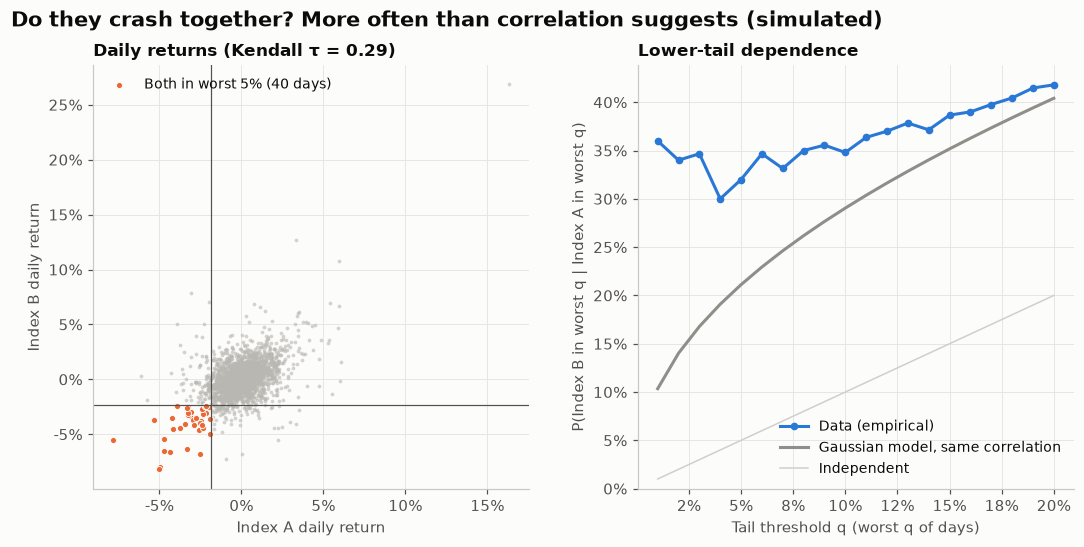

In [3]:
a, b = rets.columns
ua = rets[a].rank() / (len(rets) + 1)
ub = rets[b].rank() / (len(rets) + 1)
tau = stats.kendalltau(rets[a], rets[b]).statistic
rho_g = np.sin(np.pi * tau / 2)                              # Gaussian copula with the same Kendall tau
qs = np.linspace(0.01, 0.20, 20)
empirical = [((ua <= q) & (ub <= q)).sum() / (ua <= q).sum() for q in qs]
mvn = stats.multivariate_normal([0, 0], [[1, rho_g], [rho_g, 1]])
gaussian = [mvn.cdf([stats.norm.ppf(q)] * 2) / q for q in qs]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.5, 5), gridspec_kw={"wspace": 0.25})
qa, qb = rets[a].quantile(0.05), rets[b].quantile(0.05)
crash = (rets[a] <= qa) & (rets[b] <= qb)
ax1.scatter(rets.loc[~crash, a], rets.loc[~crash, b], s=6, color="#b8b7b1", alpha=0.6, linewidth=0)
ax1.scatter(rets.loc[crash, a], rets.loc[crash, b], s=16, color=PALETTE[1], edgecolor="#fcfcfb",
            linewidth=0.6, label=f"Both in worst 5% ({crash.sum()} days)")
ax1.axvline(qa, color="#52514e", linewidth=0.8)
ax1.axhline(qb, color="#52514e", linewidth=0.8)
for ax_, fmt in ((ax1.xaxis, None), (ax1.yaxis, None)):
    ax_.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax1.set_xlabel(f"{a} daily return")
ax1.set_ylabel(f"{b} daily return")
ax1.set_title(f"Daily returns (Kendall τ = {tau:.2f})", fontsize=11)
ax1.legend(loc="upper left", fontsize=9)

ax2.plot(qs, empirical, color=PALETTE[0], marker="o", markersize=4, label="Data (empirical)")
ax2.plot(qs, gaussian, color="#8f8e88", label="Gaussian model, same correlation")
ax2.plot(qs, qs, color="#d0cfca", linewidth=1, label="Independent")
ax2.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax2.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax2.set_xlabel("Tail threshold q (worst q of days)")
ax2.set_ylabel(f"P({b} in worst q | {a} in worst q)")
ax2.set_title("Lower-tail dependence", fontsize=11)
ax2.set_ylim(0, None)
ax2.legend(loc="lower right", fontsize=9)
fig.suptitle("Do they crash together? More often than correlation suggests (simulated)", x=0.06,
             ha="left", fontsize=14, fontweight="bold")
plt.show()

## How to read it

Left: orange points are days when both indices were in their worst 5%. There are more of them than a normal model would produce. Right: at every threshold the blue line (data) sits above the gray line (Gaussian model with the same correlation). At the 5% level, a crash in A comes with a crash in B roughly one and a half to two times as often as the Gaussian model predicts.

---
Standalone script: [`tail_dependence.py`](tail_dependence.py) &nbsp;·&nbsp; [Catalogue](../../README.md) &nbsp;·&nbsp; [Gallery](../../gallery/index.html)